# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AmaanJilani1/flyrank-ml-internship/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

*Lane: Refresh / Content Opportunity Scoring. Label: page impressions fell more than 20% (last 30d vs prior 30d). Language: observed, measured, directional, decision-support.*

## 1. Question

**Research question:** *Which pages are worth a refresh review, based on their recent search trajectory?*

**Decision supported:** a content team has limited hours each cycle. Which pages should a person look at first?

**Label (observed):** a page "declines" if its Search Console impressions in the last 30 days are more than 20% below the prior 30 days (`trend_direction == "down"`). **Prediction setup:** score each page using only information from *before* the last 30 days (days 31-90), then check against what happened.

In [1]:

import pandas as pd, numpy as np, os, warnings
warnings.filterwarnings("ignore")
URL = "https://raw.githubusercontent.com/AmaanJilani1/flyrank-ml-internship/main/data/raw/content_refresh_anonymized.csv"
df = pd.read_csv(URL)

# TARGET only. trend_direction is the label source -> never a feature.
df["y"] = (df["trend_direction"] == "down").astype(int)

# Clean past windows. The 90d total = days 1-30 (last30) + 31-60 (prev30) + 61-90 (old).
# Subtracting gives a window that is strictly BEFORE the label window.
for a, b in [("imp", "impressions"), ("clk", "clicks"), ("ses", "sessions")]:
    df[a + "_old"]  = df[b + "_90d"] - df[b + "_last_30d"] - df[b + "_prev_30d"]   # days 61-90 ago
    df[a + "_prev"] = df[b + "_prev_30d"]                                          # days 31-60 ago

# Eligibility: a page can only "decline" if it had visibility to lose.
FLOOR = 100
el = df[df["imp_prev"] >= FLOOR].copy().reset_index(drop=True)
print(f"all pages: {len(df):,} | eligible (prev30 impressions >= {FLOOR}): {len(el):,} "
      f"| clients: {el.client_id.nunique()} | decline base rate: {el.y.mean():.3f}")


from sklearn.ensemble import HistGradientBoostingClassifier as HGB
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Raw columns the features are built from. Everything is from BEFORE the label window.
SOURCES = ["imp_old","imp_prev","clk_old","clk_prev","ses_old","ses_prev","search_volume","competition",
           "cpc","word_count","content_age_days","days_since_last_update","content_type","main_intent"]
FORBIDDEN = {"trend_direction","trend_pct","impressions_last_30d","clicks_last_30d","sessions_last_30d",
             "impressions_90d","clicks_90d","sessions_90d","ctr","avg_position","engagement_rate",
             "scroll_rate","ai_traffic_pct","impression_tier","position_tier","y"}
assert not (set(SOURCES) & FORBIDDEN), "a forbidden column is feeding the features"

def make_features(d):
    X = pd.DataFrame(index=d.index)
    for a in ["imp", "clk", "ses"]:
        X["log_" + a + "_old"]  = np.log1p(d[a + "_old"])
        X["log_" + a + "_prev"] = np.log1p(d[a + "_prev"])
        X[a + "_momentum"] = X["log_" + a + "_prev"] - X["log_" + a + "_old"]   # >0 growing, <0 falling
    X["ctr_old"]  = d.clk_old  / d.imp_old.clip(lower=1)
    X["ctr_prev"] = d.clk_prev / d.imp_prev.clip(lower=1)
    X["ctr_delta"] = X.ctr_prev - X.ctr_old
    X["log_search_volume"] = np.log1p(d.search_volume)
    X["competition"], X["cpc"] = d.competition, d.cpc
    X["word_count"], X["wc_missing"] = d.word_count, d.word_count.isna().astype(int)
    X["content_age_days"] = d.content_age_days
    X["updated_over_30d_ago"] = (d.days_since_last_update > 30).astype(int)  # 0 = updated INSIDE the label window
    X["is_keyword_article"]  = (d.content_type == "keyword article").astype(int)
    X["is_comparison"]       = (d.content_type == "comparison article").astype(int)
    for v in ["informational", "transactional", "commercial", "navigational"]:
        X["intent_" + v] = (d.main_intent == v).astype(int)
    return X

X, y, g = make_features(el), el["y"].values, el["client_id"].values

def precision_at_k(y, s, k):
    return y[np.argsort(-s, kind="stable")[:k]].mean()

def cv_scores(model_fn, X, y, g, split="group", n=5, seed=0):
    """Out-of-fold probabilities. split='group' = client holdout (honest); 'random' = leaky comparison."""
    oof = np.zeros(len(y))
    sp = GroupKFold(n).split(X, y, g) if split == "group" else StratifiedKFold(n, shuffle=True, random_state=seed).split(X, y)
    for tr, te in sp:
        m = model_fn(); m.fit(X.iloc[tr], y[tr]); oof[te] = m.predict_proba(X.iloc[te])[:, 1]
    return oof

make_lr  = lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=500))
make_hgb = lambda: HGB(max_iter=200, learning_rate=0.05, max_depth=4, random_state=0)

def report(name, s, y=y):
    return {"model": name, "ROC-AUC": roc_auc_score(y, s), "PR-AUC": average_precision_score(y, s),
            "P@50": precision_at_k(y, s, 50), "P@100": precision_at_k(y, s, 100), "P@500": precision_at_k(y, s, 500)}

# Baselines (no fitting): A = the original ML-07 rule, B = "last period's drop continues"
score_rule = ((el.days_since_last_update >= 180) & (el.impressions_90d >= 500)).astype(float).values * el.impressions_90d.values
score_persist = (-X["imp_momentum"]).values

print("Label definition check: prior-30d impressions >= 100 are 'eligible'; decline = last30 < 0.8 * prev30.")
print(df.trend_direction.value_counts().to_string())


all pages: 30,000 | eligible (prev30 impressions >= 100): 18,010 | clients: 30 | decline base rate: 0.616


Label definition check: prior-30d impressions >= 100 are 'eligible'; decline = last30 < 0.8 * prev30.
trend_direction
down      16262
stable     5962
up         4388
new        2236
flat       1152


## 2. Data

**Release:** the anonymized starter slice `content_refresh_anonymized.csv` (one row per page, 30,000 pages, 32 pseudonymized clients; trailing 90-day windows from Google Search Console and GA4). **Windows:** last 30 days (label), days 31-60 and days 61-90 (features; the last one is derived as 90-day total minus the other two). **Excluded and why:** pages with <100 impressions in days 31-60 (no visibility to lose, and zero-prior pages cannot decline); every `*_last_30d`, `*_90d`, `ctr`, `avg_position`, tier and trend column from the features, because they contain the label window; IDs except for grouping. Public-safe: no client names, domains, URLs or queries.

In [2]:

excl = pd.DataFrame({"step": ["all pages", "dropped: prev30 impressions == 0", "dropped: 0 < prev30 < 100", "eligible pages used"],
                     "pages": [len(df), int((df.imp_prev == 0).sum()), int(((df.imp_prev > 0) & (df.imp_prev < FLOOR)).sum()), len(el)]})
print(excl.to_string(index=False))
print(f"\nclients in eligible set: {el.client_id.nunique()} | largest client holds {el.client_id.value_counts(normalize=True).iloc[0]:.0%} of eligible pages")
print(f"keyword-field missingness is by content type (feedly articles have none): "
      f"{df[df.content_type=='feedly article'].search_volume.isna().mean():.0%} missing for feedly vs {df[df.content_type=='keyword article'].search_volume.isna().mean():.0%} for keyword articles")


                            step  pages
                       all pages  30000
dropped: prev30 impressions == 0   3388
       dropped: 0 < prev30 < 100   8602
             eligible pages used  18010

clients in eligible set: 30 | largest client holds 32% of eligible pages
keyword-field missingness is by content type (feedly articles have none): 100% missing for feedly vs 1% for keyword articles


## 3. Methodology

**Assumptions:** the 30-day windows are comparable; pages are independent within a client only loosely (so I validate by client). **Features (25, past-window only):** log impressions/clicks/sessions for days 61-90 and 31-60, their momentum (change between windows), CTR levels and change, keyword volume/competition/CPC, word count (+ missing flag), content age, an "updated more than 30 days ago" flag, content type, search intent. **Label:** decline >20% (last 30d vs prior 30d). **Baselines:** (A) the old rule "stale ≥180 days and visible"; (B) persistence "last period's drop continues". **Models:** logistic regression (final, explainable) and gradient boosting (check). **Validation:** client-holdout 5-fold (no client in both train and test), plus a random-split run to measure client leakage, a shuffle-label test and a deliberate-leak test. **Not possible here:** time-aware splits (one snapshot per page).

In [3]:

folds = list(GroupKFold(5).split(X, y, g))
assert all(not set(g[tr]) & set(g[te]) for tr, te in folds)
print("client-holdout folds verified (no client on both sides). Features:", X.shape[1])
oof_lr, oof_hgb = cv_scores(make_lr, X, y, g, "group"), cv_scores(make_hgb, X, y, g, "group")
rand_lr, rand_hgb = cv_scores(make_lr, X, y, g, "random"), cv_scores(make_hgb, X, y, g, "random")
Xl = X.copy()
for c in ["impressions_last_30d", "clicks_last_30d", "sessions_last_30d"]: Xl[c] = el[c]
Xl["impressions_90d"] = el.impressions_90d
leaky_auc = roc_auc_score(y, cv_scores(make_hgb, Xl, y, g, "group"))
shuf_auc = roc_auc_score(np.random.RandomState(1).permutation(y), cv_scores(make_hgb, X, np.random.RandomState(1).permutation(y), g, "group"))
print(f"leakage checks -> deliberate leak AUC {leaky_auc:.3f} (never ship) | shuffled-label AUC {shuf_auc:.3f} (should be ~0.5)")


client-holdout folds verified (no client on both sides). Features: 25


leakage checks -> deliberate leak AUC 0.998 (never ship) | shuffled-label AUC 0.492 (should be ~0.5)


## 4. Results (vs baseline)

On pages from clients the model never saw, the logistic model ranks later decliners better than both baselines (ROC-AUC 0.61 vs 0.50 and 0.57; precision@100 0.85 vs 0.65 and 0.64; base rate 0.62). Gradient boosting adds nothing (0.615 AUC), so the simple model is the one I ship. A random split would have flattered the result (AUC up to 0.72), which is the client leakage I avoided. The advantage fades with depth (P@500 0.80) and the scores are over-confident at the top, so they are a ranking, not probabilities.

In [4]:

results = pd.DataFrame([report("random (reference)", np.random.RandomState(0).rand(len(y))),
                        report("A: stale>=180 & visible", score_rule), report("B: persistence", score_persist),
                        report("Logistic regression (client holdout)", oof_lr), report("Gradient boosting (client holdout)", oof_hgb),
                        report("Logistic regression (random split, optimistic)", rand_lr), report("Gradient boosting (random split, optimistic)", rand_hgb)])
print(f"base rate {y.mean():.3f}"); print(results.round(3).to_string(index=False))


base rate 0.616
                                         model  ROC-AUC  PR-AUC  P@50  P@100  P@500
                            random (reference)    0.495   0.610  0.46   0.53  0.590
                       A: stale>=180 & visible    0.501   0.616  0.76   0.65  0.604
                                B: persistence    0.567   0.665  0.66   0.64  0.636
          Logistic regression (client holdout)    0.612   0.701  0.88   0.85  0.804
            Gradient boosting (client holdout)    0.615   0.692  0.82   0.74  0.696
Logistic regression (random split, optimistic)    0.682   0.762  0.94   0.88  0.882
  Gradient boosting (random split, optimistic)    0.716   0.796  0.90   0.93  0.942


## 5. Limitations

This is an **observed, directional, decision-support** result. (1) One snapshot per page: no rolling-origin, time-aware validation, so I cannot show the signal holds across periods. (2) 30 clients, one holds ~a third of pages; results vary by fold and per-client AUC is 0.59-0.67. (3) Modest signal: ROC-AUC ~0.61, not a strong predictor. (4) Impressions can fall for seasonal, technical or demand reasons that this data cannot see. (5) About 60% of pages were edited inside the label window, a possible confound. (6) Scores are not calibrated probabilities. (7) **No causal claim:** nothing here shows a refresh changes traffic, and nothing here describes how Google's algorithm works.

In [5]:

print("Per-client AUC (clients with 200+ pages):")
pc = [(len(d), roc_auc_score(d.y, d.s)) for c, d in el.assign(s=oof_lr).groupby("client_id") if len(d) >= 200 and d.y.nunique() > 1]
print(f"  {len(pc)} clients, AUC min {min(a for _, a in pc):.2f} / max {max(a for _, a in pc):.2f}")
print(f"Pages edited inside the label window (days_since_last_update <= 30): {(el.days_since_last_update <= 30).mean():.0%}")


Per-client AUC (clients with 200+ pages):
  10 clients, AUC min 0.59 / max 0.67
Pages edited inside the label window (days_since_last_update <= 30): 61%


## 6. Ranked recommendations

The playbook: every eligible page gets an out-of-fold risk score, plain-language reason codes and an action tier (`REFRESH_REVIEW`, `REVIEW_METADATA`, `MONITOR`, `PROTECT`, `NO_ACTION`). A person should check seasonality, technical health and recent edits before changing anything.

In [6]:

oof = cv_scores(make_lr, X, y, g, "group")
el["risk_score"] = oof
el["risk_pct"] = pd.Series(oof).rank(pct=True).values

c_drop  = X.imp_momentum < -0.3                         # impressions fell >26% from days 61-90 to 31-60
c_vol   = el.imp_prev >= 2000                           # a lot of traffic at stake
c_click = (X.clk_momentum < -0.3) & (el.clk_old >= 5)   # clicks falling on a page with enough clicks to trust
c_ctr   = (el.imp_prev >= 1000) & (el.clk_prev == 0)    # visible, but earns no clicks
c_grow  = X.imp_momentum > 0.2

def codes(i):
    out = []
    if c_drop.iloc[i]:  out.append("PAST_DROP_CONTINUING")
    if c_click.iloc[i]: out.append("CLICKS_FALLING")
    if c_vol.iloc[i]:   out.append("HIGH_TRAFFIC_AT_STAKE")
    if c_ctr.iloc[i]:   out.append("VISIBLE_NO_CLICKS")
    return "|".join(out) if out else "MODEL_RISK_ONLY"
el["reason_code"] = [codes(i) for i in range(len(el))]

def action(i):
    r, p = el.risk_pct.iloc[i], el.reason_code.iloc[i]
    if r >= 0.80 and "VISIBLE_NO_CLICKS" in p: return "REVIEW_METADATA"
    if r >= 0.80: return "REFRESH_REVIEW"
    if r >= 0.50: return "MONITOR"
    if c_grow.iloc[i] and r < 0.30: return "PROTECT"
    return "NO_ACTION"
el["action"] = [action(i) for i in range(len(el))]
order = {"REFRESH_REVIEW": 0, "REVIEW_METADATA": 1, "MONITOR": 2, "PROTECT": 3, "NO_ACTION": 4}
queue = el.assign(_o=el.action.map(order)).sort_values(["_o", "risk_score", "imp_prev"], ascending=[True, False, False]).drop(columns="_o")

summary = queue.groupby("action").agg(pages=("y", "size"), decline_rate=("y", "mean"), median_prev30_impressions=("imp_prev", "median")).round(3)
print(f"base decline rate {y.mean():.3f}"); print(summary.loc[list(order)].to_string())
print("\nTop 15 queue (ids are pseudonymous):")
print(queue.head(15)[["content_id", "action", "reason_code", "risk_score", "imp_old", "imp_prev"]].round(3).to_string(index=False))
os.makedirs("work/outputs/figs", exist_ok=True)
queue[["content_id", "action", "reason_code", "risk_score", "imp_old", "imp_prev"]].round(4).to_csv("work/outputs/refresh_action_queue.csv", index=False)
summary.to_csv("work/outputs/action_summary.csv"); results.round(4).to_csv("work/outputs/results_table.csv", index=False)


base decline rate 0.616
                 pages  decline_rate  median_prev30_impressions
action                                                         
REFRESH_REVIEW    3046         0.709                      736.0
REVIEW_METADATA    557         0.808                     1742.0
MONITOR           5403         0.680                      597.0
PROTECT           1537         0.450                     1163.0
NO_ACTION         7467         0.551                      874.0

Top 15 queue (ids are pseudonymous):
          content_id         action                                reason_code  risk_score  imp_old  imp_prev
content_d8fe64aaac6b REFRESH_REVIEW                       PAST_DROP_CONTINUING       0.972     1651       850
content_e454bc31017a REFRESH_REVIEW                       PAST_DROP_CONTINUING       0.972      801       405
content_faed35c8b372 REFRESH_REVIEW                       PAST_DROP_CONTINUING       0.967      423       238
content_900f828b925b REFRESH_REVIEW               

## 7. Artifacts the paper embeds

Four charts saved to `work/outputs/figs/` (download from Colab's Files panel and commit them): model vs baselines, honest vs optimistic split, calibration, and decline rate by action tier.

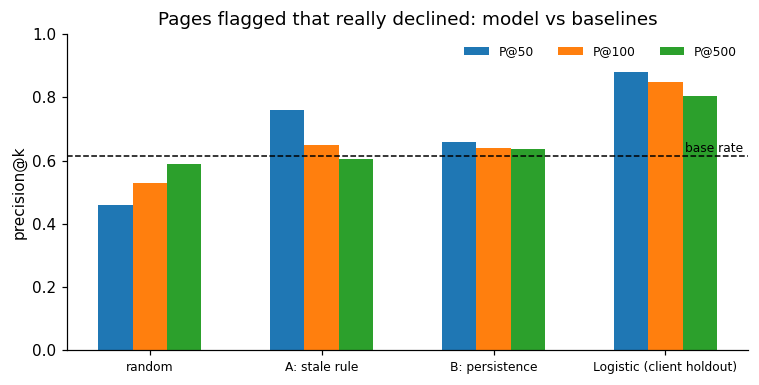

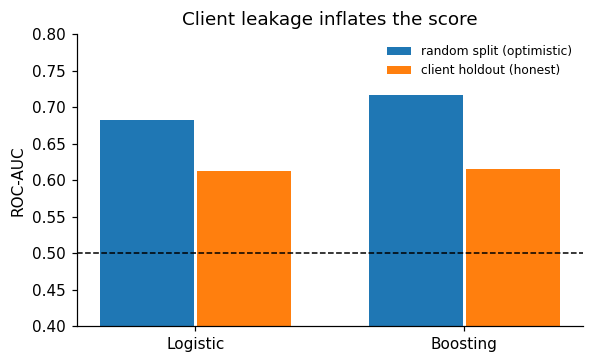

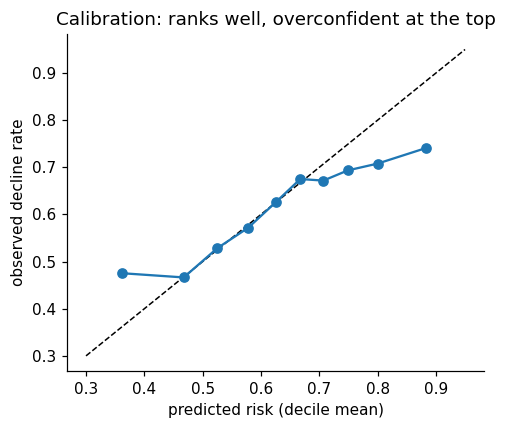

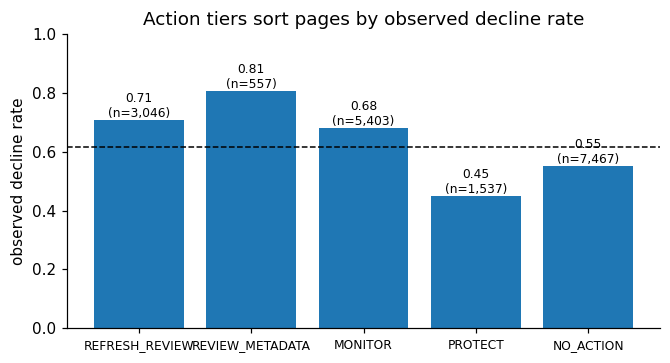

In [7]:

import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
# 1 model vs baselines
fig, ax = plt.subplots(figsize=(7, 3.6)); w = 0.2
names = ["random", "A: stale rule", "B: persistence", "Logistic (client holdout)"]
sub = results.iloc[:4]
for i, k in enumerate(["P@50", "P@100", "P@500"]): ax.bar(np.arange(4) + (i - 1) * w, sub[k], w, label=k)
ax.axhline(y.mean(), color="k", ls="--", lw=1); ax.text(3.45, y.mean() + .01, "base rate", ha="right", fontsize=8)
ax.set_xticks(range(4)); ax.set_xticklabels(names, fontsize=8); ax.set_ylim(0, 1); ax.set_ylabel("precision@k"); ax.legend(frameon=False, fontsize=8, ncol=3)
ax.set_title("Pages flagged that really declined: model vs baselines"); plt.tight_layout(); plt.savefig("work/outputs/figs/fig1_model_vs_baseline.png"); plt.show()
# 2 honest vs optimistic
fig, ax = plt.subplots(figsize=(5.5, 3.4))
v = results.set_index("model")["ROC-AUC"]
labels = ["Logistic", "Boosting"]; hon = [v["Logistic regression (client holdout)"], v["Gradient boosting (client holdout)"]]; opt = [v["Logistic regression (random split, optimistic)"], v["Gradient boosting (random split, optimistic)"]]
ax.bar(np.arange(2) - .18, opt, .35, label="random split (optimistic)"); ax.bar(np.arange(2) + .18, hon, .35, label="client holdout (honest)")
ax.axhline(.5, color="k", ls="--", lw=1); ax.set_xticks(range(2)); ax.set_xticklabels(labels); ax.set_ylim(.4, .8); ax.set_ylabel("ROC-AUC"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Client leakage inflates the score"); plt.tight_layout(); plt.savefig("work/outputs/figs/fig2_honest_vs_random_split.png"); plt.show()
# 3 calibration
cal = pd.DataFrame({"p": oof_lr, "y": y}); cal["d"] = pd.qcut(cal.p, 10, labels=False, duplicates="drop"); c = cal.groupby("d").mean()
fig, ax = plt.subplots(figsize=(4.6, 4)); ax.plot([.3, .95], [.3, .95], "k--", lw=1); ax.plot(c.p, c.y, "o-")
ax.set_xlabel("predicted risk (decile mean)"); ax.set_ylabel("observed decline rate"); ax.set_title("Calibration: ranks well, overconfident at the top")
plt.tight_layout(); plt.savefig("work/outputs/figs/fig3_calibration.png"); plt.show()
# 4 by action tier
fig, ax = plt.subplots(figsize=(6.2, 3.4)); s2 = summary.loc[list(order)]
ax.bar(s2.index, s2.decline_rate); ax.axhline(y.mean(), color="k", ls="--", lw=1)
for i, (r, n) in enumerate(zip(s2.decline_rate, s2.pages)): ax.text(i, r + .01, f"{r:.2f}\n(n={n:,})", ha="center", fontsize=8)
ax.set_ylim(0, 1); ax.set_ylabel("observed decline rate"); ax.set_title("Action tiers sort pages by observed decline rate"); plt.xticks(fontsize=8); plt.tight_layout()
plt.savefig("work/outputs/figs/fig4_action_tiers.png"); plt.show()


## ML-12 — Demo outline (5 minutes)

1. **0:00 The decision (30s):** a content team has hours, not weeks. Which pages first?
2. **0:30 The data and the trap (60s):** 30 anonymized clients, 18,010 pages. The label is a 20%+ impressions drop; the last 30 days *define* it, so I never let them into a feature.
3. **1:30 The baseline that fooled me (45s):** my first rule ("stale + visible") looked 94% accurate, on 17 pages, and staleness turned out to be a *negative* signal overall.
4. **2:15 Honest validation (60s):** random split 0.72 AUC, client-holdout 0.61. Same model; the difference is leakage. Deliberate-leak test hits 0.998.
5. **3:15 Result (45s):** logistic model, top-100 precision 0.85 vs 0.64 for "drop continues" (base 0.62). Simple model matches boosting.
6. **4:00 The playbook (45s):** five action tiers with reason codes; REVIEW_METADATA tier 0.81 observed decline rate, PROTECT 0.45.
7. **4:45 Limits and close (15s):** directional, not causal, not about Google's algorithm.

## ML-12 — Social post cut

I built a model to rank which web pages are worth a refresh review, then tried to break my own result. A random train/test split said 0.72 AUC. Holding out whole clients said 0.61. Adding one "future" column said 0.998 (a leak, not a win). The honest model still beats a simple baseline (top-100 precision 0.85 vs 0.64) and every score comes with a plain-English reason. Observed and directional, not causal.

Built on the FlyRank ML Internship dataset (flyrank.ai). #MachineLearning #DataScience #SearchData

## ML-12 — Employer-facing summary (3 sentences)

I built and deployed a leakage-aware ranking model on anonymized real search data from 30 clients (18,010 pages) that prioritizes which pages a content team should review first. Under client-holdout validation it beat a persistence baseline (ROC-AUC 0.61 vs 0.57; precision@100 0.85 vs 0.64), and I documented how a naive random split and a label-window leak inflate the score to 0.72 and 0.998. I turned the model into a five-tier action playbook with reason codes, monitoring triggers and an explicit no-causal-claims limitation.

## Self-check

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [x] ML-12 done in this notebook's closing cells (demo outline, social post, employer summary).
- [ ] Deployed paper has all 9 sections including the flyrank.ai credit (next step).